# Portfolio Exposure

## Research question
How does production-price coincidence change commercial exposure?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
Energy=MW x hours; generator P&L=(spot-reference)xMWh; purchaser reverses sign. Capture price=sum(price x MWh)/sum(MWh). Loss VaR is an empirical quantile; ES averages the fractional worst tail. Complete local delivery days respect DST.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.portfolio.risk import risk_summary
s=pd.read_csv('reports/portfolio_scenario_comparison.csv')
display(pd.DataFrame([dict(case=name,**risk_summary(g.pnl_eur)) for name,g in s.groupby('case')]))
capture=pd.read_csv('reports/renewable_capture_price_analysis.csv')
display(capture.loc[capture.period.eq('all')])

,case,scenarios,confidence,mean_pnl_eur,var_loss_eur,expected_shortfall_loss_eur
0,purchaser,1418,0.95,114.246199,1580.629375,2698.767017
1,solar,1418,0.95,-145.545859,579.511499,754.997002
2,wind,1418,0.95,-124.282194,828.248408,1274.908517


,case,period,intervals,energy_mwh,capture_price_eur_mwh,baseload_price_eur_mwh,negative_energy_share,spot_cash_eur,reference_eur_mwh
0,purchaser,all,136128,34032.000000,95.239742,95.239742,0.052825,3.241199e+06,100.0
5,solar,all,136128,4755.565065,56.601576,95.239742,0.186880,2.691725e+05,100.0
10,wind,all,136128,9977.608650,82.337236,95.239742,0.059955,8.215287e+05,100.0


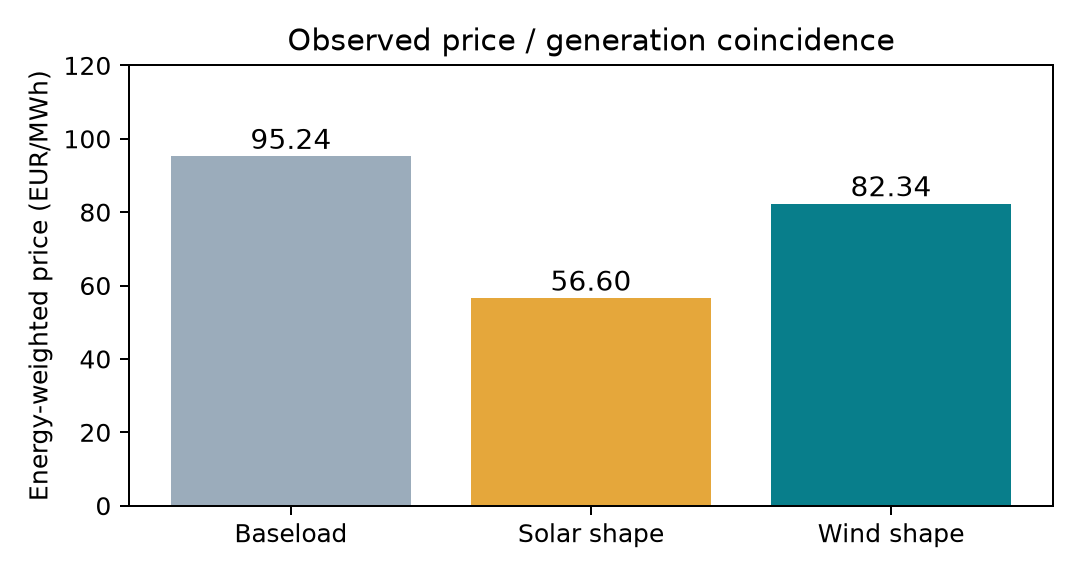

In [3]:
display(Image(filename='reports/capture_price_comparison.png'))

## Quantitative findings and commercial interpretation
Solar-shaped capture is EUR 56.60/MWh and wind-shaped capture EUR 82.34/MWh, versus baseload EUR 95.24/MWh. National generation coincidence highlights the limitations of flat-price revenue assumptions.

## Limitations
Profiles are hypothetical national shapes normalized to 1 MW observed peak, not installed capacity or actual plant profits. No fees, subsidies, imbalance or curtailment optimization. Equal peak MW does not equalize energy exposure.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.